<a href="https://colab.research.google.com/github/Cyber-GenAI/machine-learning/blob/main/Classification/APT_Intent_Classification_from_Group_Campain_Sectors_v1_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intent-Based Classification of APT Target Sectors

**Objective:** Construct a campaign-level dataset (839 rows) labeled by intent and enriched with TTP and specificity data for the machine learning phase.

**Primary Output:** `apt_total_specificity_apt_category_v19.2.xlsx` containing the following columns:
`group_id, group_name, group_type, aliases, processed_sequence_unique_tokens, total_specificity, sector_name, intent_class, apt_category, all_intent_classes, n_campaigns, n_intent_classes`

## 1. Import Libraries

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import json
import ast
from pathlib import Path
from collections import Counter, defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 80)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 2. Paths

Enable Drive paths in Colab.

In [6]:
# === Current Environment ===
BASE = Path('/content/drive/MyDrive/cyber_genai/.data/cyber_data')
OUT  = Path('/content/drive/MyDrive/cyber_genai/.data/cyber_data/artifacts')

# === Colab (uncomment if needed) ===
# from google.colab import drive
# drive.mount('/content/drive')
# BASE = Path('/content/drive/MyDrive/cyber_genai/.data/cyber_data')
# OUT  = Path('/content/drive/MyDrive/cyber_genai/.data/cyber_data/.xlsx')

GRAPHQL_JSON   = BASE / '.json'/'apt_target_sectors.json'          # or BASE/'.json'/...
SPEC_XLSX      = BASE / '.xlsx'/'apt_total_specificity_v19.2.xlsx'
TECH_XLSX      = BASE / '.xlsx'/'technique_analysis_v19.2.xlsx'

OUT_XLSX = OUT / 'apt_total_specificity_apt_group_category_v19.2.xlsx'
OUT_CSV  = OUT / 'apt_intent_labeled_from_sectors.csv'

print('GraphQL:', GRAPHQL_JSON.exists())
print('Spec:   ', SPEC_XLSX.exists())
print('Tech:   ', TECH_XLSX.exists())

GraphQL: True
Spec:    True
Tech:    True


## 3. Sector → Intent Mapping (16 classes, excluding "Other")

In [7]:
SECTOR_TO_INTENT = {
    'Government': 'Government / Public Sector', 'Political': 'Government / Public Sector',
    'public sector': 'Government / Public Sector', 'Public Services': 'Government / Public Sector',
    'Human Rights': 'Government / Public Sector', 'Humanitarian': 'Government / Public Sector',
    'NGO': 'Government / Public Sector', 'Religious': 'Government / Public Sector',
    'Journalists': 'Government / Public Sector', 'Social Services': 'Government / Public Sector',
    'Defense': 'Defense & Military', 'Defence': 'Defense & Military', 'Military': 'Defense & Military',
    'Finance': 'Financial Services', 'Financial': 'Financial Services', 'Banking': 'Financial Services',
    'Bank': 'Financial Services', 'Banking & Finance': 'Financial Services',
    'Financial Services': 'Financial Services', 'Investment': 'Financial Services',
    'Fintech': 'Financial Services', 'Insurance': 'Financial Services',
    'Wealth Management': 'Financial Services', 'Bitcoin': 'Financial Services',
    'Crypto': 'Financial Services', 'Cryptocurrency': 'Financial Services',
    'Accounting': 'Financial Services', 'Gambling': 'Financial Services',
    'Technology': 'Technology & IT', 'Information Technology': 'Technology & IT',
    'IT': 'Technology & IT', 'Tech': 'Technology & IT', 'High Tech': 'Technology & IT',
    'Software': 'Technology & IT', 'Software Automation': 'Technology & IT',
    'Semiconductor': 'Technology & IT', 'Technical Services': 'Technology & IT',
    'Telecommunications': 'Telecommunications', 'Telecommunication': 'Telecommunications',
    'Telecoms': 'Telecommunications', 'Telecom': 'Telecommunications',
    'Communications': 'Telecommunications', 'ISPs': 'Telecommunications',
    'Healthcare': 'Healthcare & Public Health', 'Health': 'Healthcare & Public Health',
    'Medical': 'Healthcare & Public Health', 'Public Health': 'Healthcare & Public Health',
    'Biomedical': 'Healthcare & Public Health', 'Biotechnology': 'Healthcare & Public Health',
    'Pharmaceutical': 'Healthcare & Public Health', 'Pharmaceuticals': 'Healthcare & Public Health',
    'Education': 'Education & Academia', 'Higher Education': 'Education & Academia',
    'Academic': 'Education & Academia', 'Academic Institutions': 'Education & Academia',
    'Research': 'Education & Academia',
    'Energy': 'Energy & Utilities', 'Electricity': 'Energy & Utilities',
    'Oil And Gas': 'Energy & Utilities', 'Nuclear': 'Energy & Utilities',
    'Utilities': 'Energy & Utilities', 'Ics': 'Energy & Utilities',
    'Manufacturing': 'Manufacturing & Industrial', 'Industrial': 'Manufacturing & Industrial',
    'Heavy Industry': 'Manufacturing & Industrial', 'Industrial Machinery': 'Manufacturing & Industrial',
    'Chemical': 'Manufacturing & Industrial', 'Automotive': 'Manufacturing & Industrial',
    'Engineering': 'Manufacturing & Industrial', 'Construction': 'Manufacturing & Industrial',
    'Mining': 'Manufacturing & Industrial',
    'Diplomatic': 'Diplomacy & Foreign Affairs', 'Diplomacy': 'Diplomacy & Foreign Affairs',
    'Embassy': 'Diplomacy & Foreign Affairs', 'Foreign Affairs': 'Diplomacy & Foreign Affairs',
    'Foreign': 'Diplomacy & Foreign Affairs',
    'Aerospace': 'Aerospace & Aviation', 'Aviation': 'Aerospace & Aviation',
    'Airline': 'Aerospace & Aviation', 'Space': 'Aerospace & Aviation',
    'Critical Infrastructure': 'Critical Infrastructure & Transportation',
    'Commercial Facilities': 'Critical Infrastructure & Transportation',
    'Transportation': 'Critical Infrastructure & Transportation',
    'Logistics': 'Critical Infrastructure & Transportation',
    'Maritime': 'Critical Infrastructure & Transportation',
    'Shipping': 'Critical Infrastructure & Transportation',
    'Travel': 'Critical Infrastructure & Transportation',
    'Tourism': 'Critical Infrastructure & Transportation',
    'Emergency Services': 'Critical Infrastructure & Transportation',
    'Media': 'Media & Entertainment', 'Entertainment': 'Media & Entertainment',
    'Gaming': 'Media & Entertainment', 'Sports': 'Media & Entertainment',
    'Retail': 'Retail & Consumer Services', 'Consumer Services': 'Retail & Consumer Services',
    'Hospitality': 'Retail & Consumer Services', 'Hotel': 'Retail & Consumer Services',
    'Food and Beverage': 'Retail & Consumer Services',
    'Food and Agriculture': 'Agriculture & Food', 'Agriculture': 'Agriculture & Food',
    'Professional Services': 'Professional & Business Services',
    'Consulting': 'Professional & Business Services', 'Business Services': 'Professional & Business Services',
    'BPO': 'Professional & Business Services', 'Human Resources': 'Professional & Business Services',
    'Employment': 'Professional & Business Services', 'Legal': 'Professional & Business Services',
    'Law': 'Professional & Business Services', 'Architecture': 'Professional & Business Services',
    'Development': 'Professional & Business Services', 'Trade': 'Professional & Business Services',
}
print(f'Mapped keywords: {len(SECTOR_TO_INTENT)}')

Mapped keywords: 111


## 4. Load GraphQL → Campaign DataFrame (839 rows)

In [8]:
with open(GRAPHQL_JSON, encoding='utf-8') as f:
    raw = json.load(f)

edges = raw['data']['stixCoreRelationships']['edges']
print(f'Total edges: {len(edges)}')
print(f'hasNextPage: {raw["data"]["stixCoreRelationships"]["pageInfo"]["hasNextPage"]}')

rows = []
for edge in edges:
    node = edge['node']
    frm, to = node['from'], node['to']
    sector = to.get('name')
    intent = SECTOR_TO_INTENT.get(sector, 'Unmapped / Residual')
    rows.append({
        'group_id': frm.get('id'),
        'group_name': frm.get('name'),
        'group_type': frm.get('__typename'),
        'aliases': frm.get('aliases') or [],
        'sector_name': sector,
        'intent_class': intent,
    })

camp = pd.DataFrame(rows)
print(f'Campaign rows: {len(camp)}')
print(f'Unique groups: {camp["group_name"].nunique()}')
print(f'Unmapped: {(camp["intent_class"]=="Unmapped / Residual").sum()}')
camp.head(3)

Total edges: 839
hasNextPage: True
Campaign rows: 839
Unique groups: 353
Unmapped: 0


,group_id,group_name,group_type,aliases,sector_name,intent_class
0,d8b44a68-13ac-4489-b3f5-ab946535f614,Vietnamese group,IntrusionSet,[],Technology,Technology & IT
1,21b6d9bc-4d45-4ee3-b4b0-b8818a1ecd68,FIN6,IntrusionSet,"[Magecart Group 6, ITG08, Skeleton Spider, TAAL, Camouflage Tempest]",Finance,Financial Services
2,554eae2d-8e6b-4541-8637-fec8b6b72379,Multiple Russian state-backed groups,IntrusionSet,[],Telecommunications,Telecommunications


## 5. Intent Distribution (Campaign Level)

,Intent Class,# Number of Instances,Percentage
0,Government / Public Sector,148,17.6
1,Financial Services,108,12.9
2,Technology & IT,82,9.8
3,Defense & Military,66,7.9
4,Manufacturing & Industrial,66,7.9
5,Healthcare & Public Health,53,6.3
6,Telecommunications,52,6.2
7,Energy & Utilities,51,6.1
8,Critical Infrastructure & Transportation,45,5.4
9,Education & Academia,41,4.9


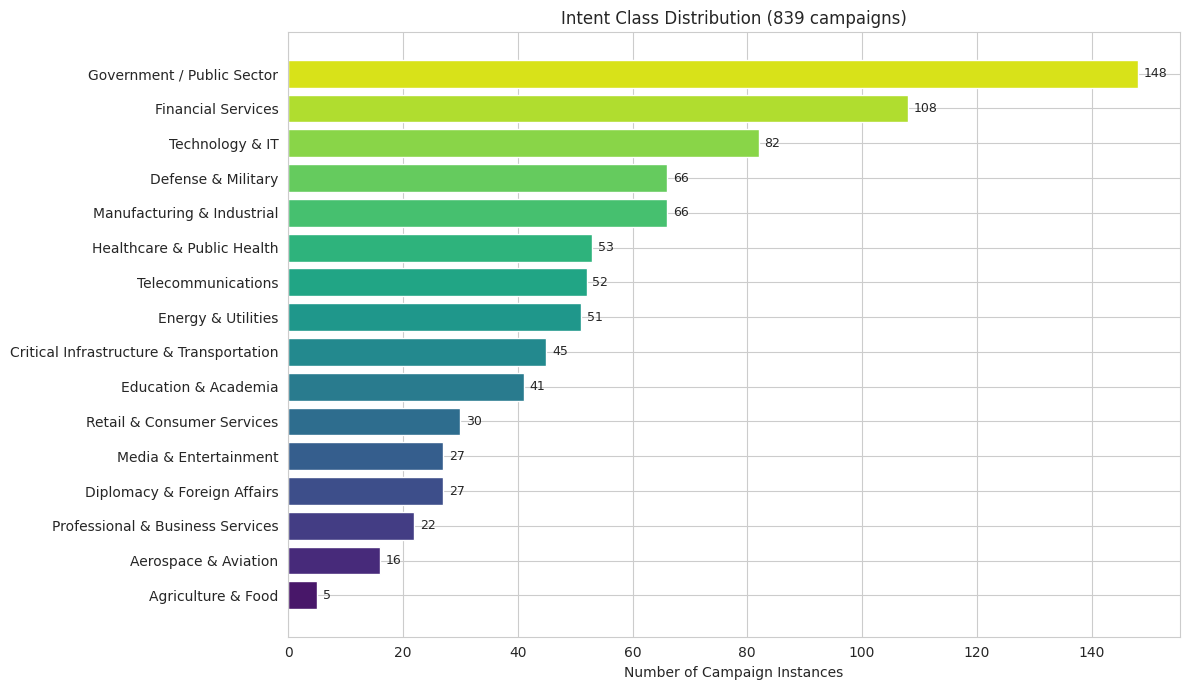

In [9]:
intent_dist = (
    camp['intent_class'].value_counts()
    .rename_axis('Intent Class')
    .reset_index(name='# Number of Instances')
)
intent_dist['Percentage'] = (intent_dist['# Number of Instances'] / len(camp) * 100).round(1)
display(intent_dist)

fig, ax = plt.subplots(figsize=(12, 7))
plot_df = intent_dist[intent_dist['Intent Class'] != 'Unmapped / Residual']
bars = ax.barh(plot_df['Intent Class'][::-1], plot_df['# Number of Instances'][::-1],
               color=sns.color_palette('viridis', len(plot_df)))
ax.set_xlabel('Number of Campaign Instances')
ax.set_title('Intent Class Distribution (839 campaigns)')
for bar, val in zip(bars, plot_df['# Number of Instances'][::-1]):
    ax.text(val + 1, bar.get_y() + bar.get_height()/2, str(val), va='center', fontsize=9)
plt.tight_layout()
plt.show()

## 6. Load Specificity + Technique weights and recalculate `total_specificity`

According to the article:
`Specificity(x) = 1 / C(x)` and `total_specificity = Σ Specificity(t)` for the group's unique TTPs.

In [10]:
tech = pd.read_excel(TECH_XLSX)
spec_weight = dict(zip(
    tech['technique_name'].astype(str),
    tech['unique_specificity_count_per_technique'].astype(float)
))
print(f'Techniques with specificity weight: {len(spec_weight)}')

spec = pd.read_excel(SPEC_XLSX)
print(f'Specificity groups: {len(spec)}')

def parse_tokens(x):
    if pd.isna(x):
        return []
    if isinstance(x, list):
        return [str(t) for t in x]
    s = str(x).strip()
    if s in ('', '[]', 'nan'):
        return []
    try:
        v = ast.literal_eval(s)
        return [str(t) for t in v] if isinstance(v, list) else []
    except Exception:
        return []

def compute_total_specificity(tokens):
    """Σ 1/C(t) for unique techniques of the group."""
    return float(sum(spec_weight.get(t, 0.0) for t in tokens))

spec['tokens'] = spec['processed_sequence_unique_tokens'].apply(parse_tokens)
spec['total_specificity_recomputed'] = spec['tokens'].apply(compute_total_specificity)
spec['name_key'] = spec['intrusion_set_name'].astype(str).str.strip().str.lower()

# validation
both = spec[spec['tokens'].apply(len) > 0]
diff = (both['total_specificity'] - both['total_specificity_recomputed']).abs()
print(f'Recompute check — mean abs diff: {diff.mean():.2e}  (should be ~0)')

Techniques with specificity weight: 721
Specificity groups: 819
Recompute check — mean abs diff: 2.49e-11  (should be ~0)


## 7. Lookup TTP per group (+ manual aliases)

In [11]:
name_to_ttp = {}
for _, r in spec.iterrows():
    key = r['name_key']
    toks = r['tokens']
    if not toks:
        continue
    if key not in name_to_ttp or len(toks) > len(name_to_ttp[key]['tokens']):
        name_to_ttp[key] = {
            'tokens': toks,
            'total_specificity': r['total_specificity_recomputed'],
        }

# Similarly named items in GraphQL that differ slightly in specificity
MANUAL_ALIAS = {
    'lumma': 'lummastealer',
    'sidecopy, transparent tribe (apt36)': 'transparent tribe',
}
for alias, target in MANUAL_ALIAS.items():
    if target in name_to_ttp and alias not in name_to_ttp:
        name_to_ttp[alias] = name_to_ttp[target]
if 'lumma stealer' in name_to_ttp:
    name_to_ttp['lumma'] = name_to_ttp['lumma stealer']

print(f'Groups with non-empty TTP: {len(name_to_ttp)}')

Groups with non-empty TTP: 782


## 8. Group-level aggregation (all_intent_classes, n_campaigns, …)

In [12]:
all_intents = (
    camp.groupby('group_name')['intent_class']
    .agg(lambda x: ' | '.join(sorted(set(x))))
    .to_dict()
)
n_campaigns = camp.groupby('group_name').size().to_dict()
n_intent_classes = {g: len(v.split(' | ')) for g, v in all_intents.items()}

print(f'Groups with >1 intent class: {sum(1 for v in n_intent_classes.values() if v > 1)}')

Groups with >1 intent class: 185


## 9. Constructing the Final 839-Row Table (Campaign Level + TTP)

- Each row = one campaign (targets relationship)
- `apt_category` = `intent_class` (label of the same campaign)
- `processed_sequence_unique_tokens` and `total_specificity` from the corresponding group
- Groups lacking TTP data in the Specificity file → TTP field remains empty (approximately 20 groups)

In [13]:
def enrich(row):
    key = str(row['group_name']).strip().lower()
    info = name_to_ttp.get(key, {})
    toks = info.get('tokens', [])
    tot  = info.get('total_specificity', np.nan)
    return pd.Series({
        'processed_sequence_unique_tokens': toks if toks else None,
        'total_specificity': tot if toks else np.nan,
        'apt_category': row['intent_class'],  # برابر intent_class
        'all_intent_classes': all_intents.get(row['group_name'], row['intent_class']),
        'n_campaigns': int(n_campaigns.get(row['group_name'], 1)),
        'n_intent_classes': int(n_intent_classes.get(row['group_name'], 1)),
        'has_ttp': bool(toks),
    })

extra = camp.apply(enrich, axis=1)
full = pd.concat([camp.reset_index(drop=True), extra.reset_index(drop=True)], axis=1)

print(f'Total rows: {len(full)}')
print(f'With TTP:   {full["has_ttp"].sum()}')
print(f'Without TTP:{ (~full["has_ttp"]).sum()}')
print(f'apt_category == intent_class: {(full["apt_category"] == full["intent_class"]).all()}')

Total rows: 839
With TTP:   802
Without TTP:37
apt_category == intent_class: True


In [14]:
# Preparing to save Excel/CSV
out = full.copy()
out['aliases'] = out['aliases'].apply(
    lambda x: json.dumps(x, ensure_ascii=False) if isinstance(x, list) else str(x)
)
out['processed_sequence_unique_tokens'] = out['processed_sequence_unique_tokens'].apply(
    lambda x: json.dumps(x, ensure_ascii=False) if isinstance(x, list) else ('' if x is None else str(x))
)

COLS = [
    'group_id', 'group_name', 'group_type', 'aliases',
    'processed_sequence_unique_tokens', 'total_specificity',
    'sector_name', 'intent_class', 'apt_category',
    'all_intent_classes', 'n_campaigns', 'n_intent_classes',
]
out_final = out[COLS]

display(out_final.head(5))
print('Shape:', out_final.shape)
print()
print(out_final['intent_class'].value_counts().to_string())

,group_id,group_name,group_type,aliases,processed_sequence_unique_tokens,total_specificity,sector_name,intent_class,apt_category,all_intent_classes,n_campaigns,n_intent_classes
0,d8b44a68-13ac-4489-b3f5-ab946535f614,Vietnamese group,IntrusionSet,[],"[""T1087"", ""T1090"", ""T1133"", ""T1518"", ""T1083"", ""T1056"", ""T1027"", ""T1497"", ""T1...",0.290032,Technology,Technology & IT,Technology & IT,Financial Services | Technology & IT,2,2
1,21b6d9bc-4d45-4ee3-b4b0-b8818a1ecd68,FIN6,IntrusionSet,"[""Magecart Group 6"", ""ITG08"", ""Skeleton Spider"", ""TAAL"", ""Camouflage Tempest""]","[""T1219"", ""T1588.002"", ""T1573"", ""T1204"", ""T1573.002"", ""T1124"", ""T1021"", ""T10...",1.440299,Finance,Financial Services,Financial Services,Financial Services | Manufacturing & Industrial,2,2
2,554eae2d-8e6b-4541-8637-fec8b6b72379,Multiple Russian state-backed groups,IntrusionSet,[],,NaN,Telecommunications,Telecommunications,Telecommunications,Energy & Utilities | Telecommunications,2,2
3,3560c044-68b4-4026-87fd-2860ee81fe03,Saaiwc Group,IntrusionSet,[],"[""T1204"", ""T1574.001"", ""T1132"", ""TA0011"", ""T1002""]",0.300639,Military,Defense & Military,Defense & Military,Defense & Military | Financial Services,2,2
4,42249221-0ce1-43eb-8ec2-adea44495398,AIRASHI,IntrusionSet,[],"[""T1133"", ""T1498"", ""T1573"", ""T1505.003"", ""T1095"", ""T1071"", ""T1571"", ""T1016"",...",0.215650,Gaming,Media & Entertainment,Media & Entertainment,Media & Entertainment | Technology & IT,2,2


Shape: (839, 12)

intent_class
Government / Public Sector                  148
Financial Services                          108
Technology & IT                              82
Defense & Military                           66
Manufacturing & Industrial                   66
Healthcare & Public Health                   53
Telecommunications                           52
Energy & Utilities                           51
Critical Infrastructure & Transportation     45
Education & Academia                         41
Retail & Consumer Services                   30
Media & Entertainment                        27
Diplomacy & Foreign Affairs                  27
Professional & Business Services             22
Aerospace & Aviation                         16
Agriculture & Food                            5


## 10. Saving Outputs

In [15]:
out_final.to_excel(OUT_XLSX, index=False)
out_final.to_csv(OUT_CSV, index=False)

print(f'Saved Excel → {OUT_XLSX}')
print(f'Saved CSV   → {OUT_CSV}')
print(f'Rows: {len(out_final)} | Columns: {list(out_final.columns)}')

Saved Excel → /content/drive/MyDrive/cyber_genai/.data/cyber_data/artifacts/apt_total_specificity_apt_group_category_v19.2.xlsx
Saved CSV   → /content/drive/MyDrive/cyber_genai/.data/cyber_data/artifacts/apt_intent_labeled_from_sectors.csv
Rows: 839 | Columns: ['group_id', 'group_name', 'group_type', 'aliases', 'processed_sequence_unique_tokens', 'total_specificity', 'sector_name', 'intent_class', 'apt_category', 'all_intent_classes', 'n_campaigns', 'n_intent_classes']


## 11. Report on Groups Without TTPs

For these groups, either their names did not match in the `apt_total_specificity_v19.2.xlsx` file, or the TTP list was empty.

In [16]:
no_ttp_groups = full.loc[~full['has_ttp'], 'group_name'].value_counts()
print(f'Groups without TTP: {len(no_ttp_groups)}')
print(f'Campaign rows without TTP: {(~full["has_ttp"]).sum()}')
display(no_ttp_groups.reset_index().rename(columns={'index': 'group_name', 'group_name': 'n_campaigns'}))

Groups without TTP: 20
Campaign rows without TTP: 37


,n_campaigns,count
0,Iranian,4
1,Ignoble Scorpius,3
2,Storm-0249,3
3,Larva-24005,3
4,APT45,3
5,Molatori,2
6,Multiple Russian state-backed groups,2
7,Chinese cybercriminal groups,2
8,SAMBA SPIDER,2
9,DragonForce,2


## 12. Summary of Step 1 (Ready for ML)

| Item | Value |
|------|--------|
| Number of rows (campaigns) | **839** |
| Intent classes | **16** (excluding 'Other') |
| Rows with TTPs | ~800 |
| `apt_category` | Always = `intent_class` |
| `total_specificity` | Recalculated using Σ(1/C(t)) |

**Next Step:** Constructing a feature vector from `processed_sequence_unique_tokens` using specificity weights and training a Random Forest / Gradient Boosting model.